<a href="https://colab.research.google.com/github/Rubin-S/nifty50-sma-backtester/blob/main/Quantitative_Parameter_Optimization_%26_Walk_Forward_Validation_on_NIFTY_50.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantitative Strategy Optimization & Out-of-Sample Validation
## Module 1: Environment Setup, Data Ingestion & Chronological Split

### Objective
Ingest historical price data for the **NIFTY 50** index (`^NSEI`) and split it chronologically to prevent look-ahead bias and curve-fitting:
* **In-Sample (Train):** 2018-01-01 to 2023-12-31 (~80% of data) for parameter grid search and sensitivity heatmaps.
* **Out-of-Sample (Test):** 2024-01-01 to 2026-01-01 (~20% of data) for unseen walk-forward efficiency testing.

In [1]:
# 1. Install & import required quantitative packages
!pip install yfinance seaborn -q

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Download historical daily data for NIFTY 50
ticker = "^NSEI"
df = yf.download(ticker, start="2018-01-01", end="2026-01-01", auto_adjust=True)
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# 3. Chronological Train / Test Split
df_train = df.loc['2018-01-01':'2023-12-31'].copy()
df_test = df.loc['2024-01-01':'2026-01-01'].copy()

# 4. Verify partition boundaries
print(f"Full Dataset:  {df.index.min().date()} to {df.index.max().date()} ({len(df)} trading bars)")
print(f"Train Set:     {df_train.index.min().date()} to {df_train.index.max().date()} ({len(df_train)} trading bars)")
print(f"Test Set:      {df_test.index.min().date()} to {df_test.index.max().date()} ({len(df_test)} trading bars)")

[*********************100%***********************]  1 of 1 completed

Full Dataset:  2018-01-02 to 2025-12-31 (1972 trading bars)
Train Set:     2018-01-02 to 2023-12-29 (1477 trading bars)
Test Set:      2024-01-01 to 2025-12-31 (495 trading bars)


## Module 2: The Vectorized Evaluation Engine

### Objective
Encapsulate the baseline Dual SMA backtest into a reusable Python function to rapidly compute the Sharpe ratio for any given parameter combination.

In [2]:
def evaluate_strategy(data, fast, slow, fee_bps=5):
    # 1. Work on a clean copy
    df = data.copy()

    # 2. Moving Average Indicators 📉
    df['SMA_Fast'] = df['Close'].rolling(window=fast).mean()
    df['SMA_Slow'] = df['Close'].rolling(window=slow).mean()

    # 3. Signal & Execution Lag (t+1) 🚦
    df['Raw_Signal'] = np.where(df['SMA_Fast'] > df['SMA_Slow'], 1.0, 0.0)
    df['Position'] = df['Raw_Signal'].shift(1).fillna(0.0)

    # 4. Returns & Friction 💸
    df['Market_Return'] = df['Close'].pct_change().fillna(0.0)
    df['Trades'] = df['Position'].diff().abs().fillna(0.0)
    cost_per_trade = fee_bps / 10000.0
    df['Strategy_Return'] = (df['Position'] * df['Market_Return']) - (df['Trades'] * cost_per_trade)

    # 5. Compounding & Risk Analytics ⚖️
    trading_days = 252
    n_days = len(df)
    df['Strategy_Equity'] = (1 + df['Strategy_Return']).cumprod()

    cagr = (df['Strategy_Equity'].iloc[-1]) ** (trading_days / n_days) - 1
    vol = df['Strategy_Return'].std() * np.sqrt(trading_days)

    sharpe = (cagr / vol) if vol != 0 else 0.0
    return sharpe

## Module 3: In-Sample 2D Parameter Grid Search

### Objective
Systematically evaluate candidate pairs of Fast SMA ($5 \le \text{Fast} \le 35$) and Slow SMA ($30 \le \text{Slow} \le 100$) exclusively on the training dataset (`df_train`) to measure risk-adjusted performance across the parameter space.

In [3]:
# 1. Define parameter search space 📐
fast_range = range(5, 40, 5)     # [5, 10, 15, 20, 25, 30, 35]
slow_range = range(30, 110, 10)  # [30, 40, 50, 60, 70, 80, 90, 100]

results = []

# 2. Execute Grid Search on Training Data (df_train) 🏋️
for fast in fast_range:
    for slow in slow_range:
        if fast < slow:
            sharpe = evaluate_strategy(df_train, fast, slow)
            results.append({'Fast': fast, 'Slow': slow, 'Sharpe': round(sharpe, 2)})

# 3. Convert results list to DataFrame 📊
df_results = pd.DataFrame(results)

# 4. Display the top 10 best-performing combinations on In-Sample data
top_params = df_results.sort_values(by='Sharpe', ascending=False).head(10)
top_params

,Fast,Slow,Sharpe
12,10,70,1.32
13,10,80,1.29
2,5,50,1.28
1,5,40,1.26
8,10,30,1.25
26,20,50,1.24
14,10,90,1.23
19,15,60,1.22
18,15,50,1.21
0,5,30,1.17


## Module 4: Parameter Sensitivity Heatmap

### Objective
Pivot the grid search table into a 2D matrix and render a heatmap to visually evaluate parameter stability and identify broad performance plateaus.

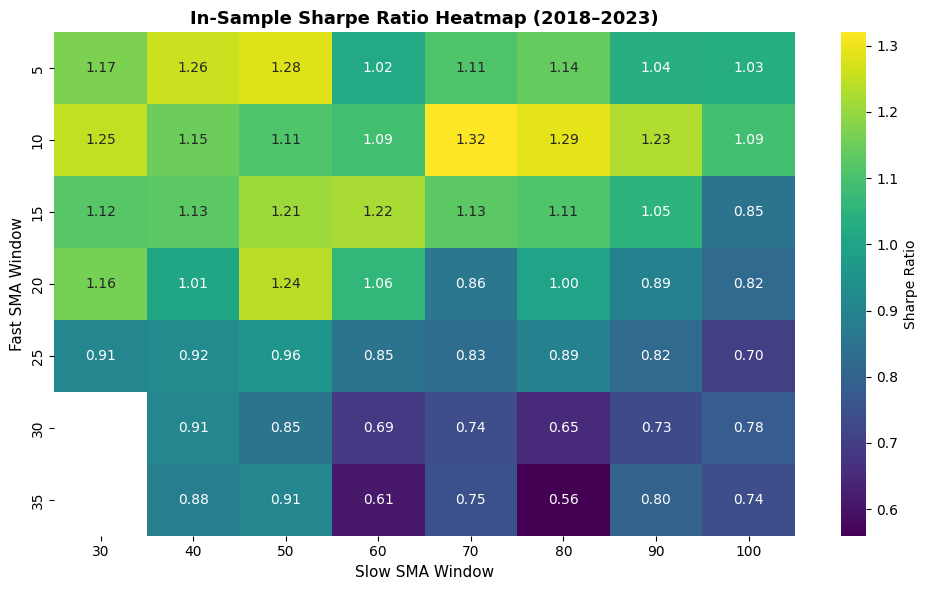

In [4]:
# 1. Reshape results into a 2D matrix 📐
heatmap_matrix = df_results.pivot(index='Fast', columns='Slow', values='Sharpe')

# 2. Render heatmap using Seaborn 🗺️
plt.figure(figsize=(10, 6))
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="viridis", cbar_kws={'label': 'Sharpe Ratio'})

# 3. Chart formatting 📊
plt.title('In-Sample Sharpe Ratio Heatmap (2018–2023)', fontsize=13, fontweight='bold')
plt.xlabel('Slow SMA Window', fontsize=11)
plt.ylabel('Fast SMA Window', fontsize=11)
plt.tight_layout()
plt.show()

## Module 5: Out-of-Sample Validation & Walk-Forward Efficiency (WFE)

### Objective
Test our optimized parameter set ($\text{Fast} = 10, \text{Slow} = 70$) on the unseen test dataset (`df_test`: 2024–2026) to quantify parameter decay and evaluate out-of-sample robustness:

$$\text{WFE} = \frac{\text{Sharpe}_{\text{OOS}}}{\text{Sharpe}_{\text{IS}}}$$

In [5]:
# 1. Select winning parameter setup from plateau 🏔️
best_fast = 10
best_slow = 70

# 2. Evaluate performance on both splits ⚖️
sharpe_is = evaluate_strategy(df_train, best_fast, best_slow)
sharpe_oos = evaluate_strategy(df_test, best_fast, best_slow)

# 3. Calculate Walk-Forward Efficiency (WFE) 📏
wfe = (sharpe_oos / sharpe_is) if sharpe_is != 0 else 0.0

# 4. Print Out-of-Sample Validation Report 📊
print("=== Parameter Generalization Report ===")
print(f"Chosen Parameters:      Fast = {best_fast} | Slow = {best_slow}")
print(f"In-Sample Sharpe (Train 2018-2023):     {sharpe_is:.2f}")
print(f"Out-of-Sample Sharpe (Test 2024-2026):  {sharpe_oos:.2f}")
print(f"Walk-Forward Efficiency (WFE):          {wfe * 100:.1f}%")

=== Parameter Generalization Report ===
Chosen Parameters:      Fast = 10 | Slow = 70
In-Sample Sharpe (Train 2018-2023):     1.32
Out-of-Sample Sharpe (Test 2024-2026):  0.46
Walk-Forward Efficiency (WFE):          35.1%


## Module 6: Out-of-Sample Equity Curve Diagnostics

### Objective
Plot the cumulative returns of the optimized Strategy ($\text{Fast} = 10, \text{Slow} = 70$) against the NIFTY 50 Buy & Hold benchmark over the test period (2024–2026) to diagnose why performance decayed.

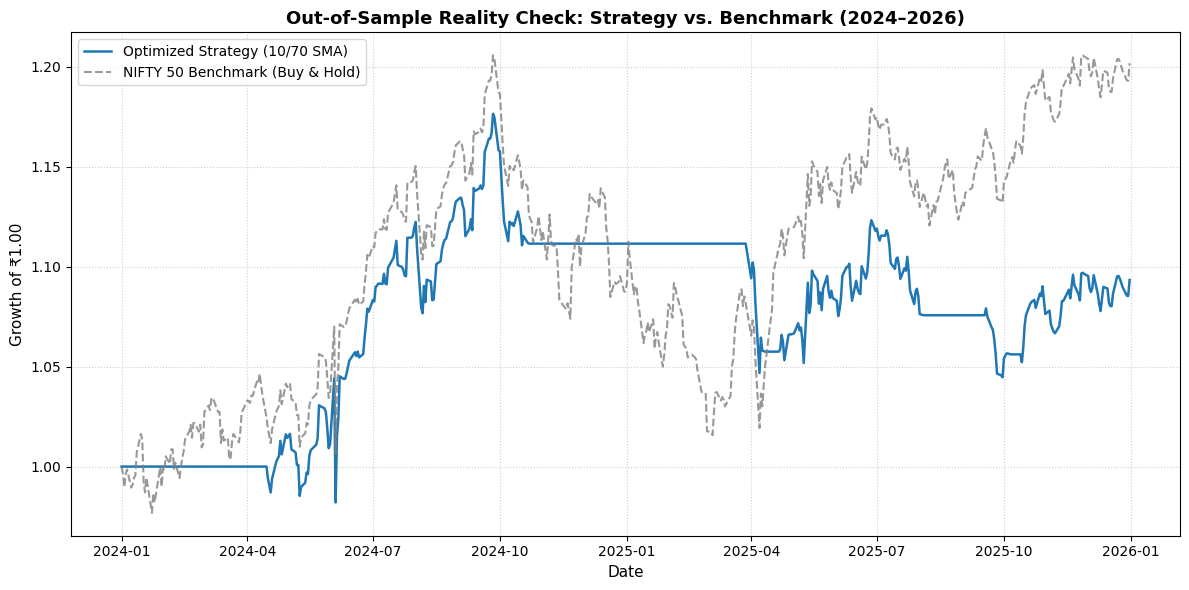

In [6]:
# 1. Run backtest calculations on test data (2024–2026) ⚙️
df_test_eval = df_test.copy()
df_test_eval['SMA_Fast'] = df_test_eval['Close'].rolling(window=10).mean()
df_test_eval['SMA_Slow'] = df_test_eval['Close'].rolling(window=70).mean()
df_test_eval['Raw_Signal'] = np.where(df_test_eval['SMA_Fast'] > df_test_eval['SMA_Slow'], 1.0, 0.0)
df_test_eval['Position'] = df_test_eval['Raw_Signal'].shift(1).fillna(0.0)

df_test_eval['Market_Return'] = df_test_eval['Close'].pct_change().fillna(0.0)
df_test_eval['Trades'] = df_test_eval['Position'].diff().abs().fillna(0.0)
cost_per_trade = 5 / 10000.0  # 5 bps
df_test_eval['Strategy_Return'] = (df_test_eval['Position'] * df_test_eval['Market_Return']) - (df_test_eval['Trades'] * cost_per_trade)

# 2. Cumulative growth curves 💰
df_test_eval['Benchmark_Equity'] = (1 + df_test_eval['Market_Return']).cumprod()
df_test_eval['Strategy_Equity'] = (1 + df_test_eval['Strategy_Return']).cumprod()

# 3. Plot Out-of-Sample Performance 📈
plt.figure(figsize=(12, 6))
plt.plot(df_test_eval.index, df_test_eval['Strategy_Equity'], label='Optimized Strategy (10/70 SMA)', color='#1f77b4', linewidth=1.8)
plt.plot(df_test_eval.index, df_test_eval['Benchmark_Equity'], label='NIFTY 50 Benchmark (Buy & Hold)', color='#7f7f7f', linestyle='--', alpha=0.8)

plt.title('Out-of-Sample Reality Check: Strategy vs. Benchmark (2024–2026)', fontsize=13, fontweight='bold')
plt.xlabel('Date', fontsize=11)
plt.ylabel('Growth of ₹1.00', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

## Module 7: Research Findings & Walk-Forward Diagnostics

### 1. In-Sample vs. Out-of-Sample Findings
* **Training Period (2018–2023):** The 2D grid search identified an optimal parameter plateau around **Fast = 10** and **Slow = 70**, generating an In-Sample Sharpe Ratio of **1.32**.
* **Testing Period (2024–2026):** On unseen out-of-sample data, the strategy achieved a Sharpe Ratio of **0.46**, resulting in a **Walk-Forward Efficiency (WFE) of 35.1%**.

### 2. Strategy Diagnostics & Regime Behavior
* **Downside Protection:** The strategy successfully avoided major drawdowns during sharp corrections by transitioning into 100% cash.
* **Lag in Quick Rebounds:** Due to the wide spread between the 10-day and 70-day moving averages, the strategy experienced entry lag during rapid market recoveries, remaining in cash while the underlying index rallied.

### 3. Quantitative Conclusion
The positive out-of-sample Sharpe ratio confirms that the edge was not purely overfit noise. However, the drop in WFE highlights the need for dynamic position sizing (such as volatility targeting) or adaptive trend indicators rather than static parameter pairs across shifting market regimes.